# o2org: full walkthrough

This notebook exercises the whole `o2org` package end to end:

1. Connecting (auth via email/password)
2. Retrieving data (`list()` / `get()` — the common case)
3. Other procedures: creating & updating records
4. Handling errors
5. Analysis shortcuts (`quick_report`, `Dataset`, statistics) — the point of the second half of the library

**About the data in this notebook:** `BASE_URL`/`VALID_EMAIL`/`VALID_PASSWORD`
below point at a real org_dma instance (a local `php artisan serve` at
`http://localhost:8000`), not a mock. It now implements the endpoints in the
README's *API contract* section (Sanctum login, full create/update routes),
so re-running this notebook top to bottom talks to a real Postgres-backed
Laravel app. The Retrieving-data section reads whatever compounds/projects
already exist in that database, so exact ids/counts will differ from a fresh
install — the code (not the specific values) is what to focus on.

## Environment setup (do this once)

This notebook needs `o2org` installed in whatever Python environment your
Jupyter kernel is running — it is **not** enough to just open this file.

From the repo root:

```bash
python3 -m venv .venv
source .venv/bin/activate        # Windows: .venv\Scripts\activate
pip install -e ".[notebook]"     # installs o2org plus jupyter/ipykernel
```

Then point Jupyter at that same environment:

- **VS Code**: click *Select Kernel* (top right of this notebook) → choose the
  `.venv` interpreter for this repo (create it first if it isn't listed —
  VS Code will offer to register it after you activate it once in a terminal).
- **Jupyter Notebook/Lab**: `Kernel` menu → `Change Kernel` → the one created
  by the steps above.

If the `import o2org` cell below fails with `ModuleNotFoundError`, the kernel
is not pointed at that environment yet — fix that before continuing, the rest
of the notebook assumes it.

## Setup

In [1]:
import pandas as pd

import o2org
from o2org.analysis import Dataset, quick_report
from o2org import AuthenticationError, NotFoundError, ValidationError

## 0. Server connection settings

Point these at your org_dma instance.

In [2]:
BASE_URL = "http://localhost:8000"
VALID_EMAIL = "anna@example.com"
VALID_PASSWORD = "admin"

## 1. Connecting

In [3]:
client = o2org.connect(
    base_url=BASE_URL,
    email=VALID_EMAIL,
    password=VALID_PASSWORD,
)
print(client)
print("authenticated:", client.is_authenticated)

<OrgClient http://localhost:8000 as anna@example.com>
authenticated: True


Credentials can also come from environment variables (`O2ORG_BASE_URL`,
`O2ORG_EMAIL`, `O2ORG_PASSWORD`) or `~/.o2org/config.ini`, so `o2org.connect()`
alone works with no arguments at all — see the README for the config file
format. Use `connect()` as a context manager to log out automatically:

In [4]:
with o2org.connect(base_url=BASE_URL, email=VALID_EMAIL, password=VALID_PASSWORD) as scoped_client:
    print("inside the with-block:", scoped_client.is_authenticated)
print("after the with-block:", scoped_client.is_authenticated)

inside the with-block: True
after the with-block: False


## 2. Retrieving data

This is what you'll use most. Every table is an attribute on `client`. `.list()`
is lazy — it never touches the network by itself. `.count()`/`.pages` make one
cheap request and read the server's own pagination total, no matter how many
pages that total spans; `.get()` (or iterating/indexing it directly, or
passing it into `Dataset`/`quick_report`) is what actually fetches the
records, as plain Python data — no DataFrame conversion step to remember.

In [5]:
first_page = client.compounds.list()
print(f"{len(first_page)} compounds on the first page:")
for row in first_page:
    print(" -", row["canonical_name"])

20 compounds on the first page:
 - Fumaric acid, butyl 3,4-dimethoxyphenyl ester
 - Eicosadienoic acid
 - 3-Methoxytyramine
 - (S)-3-Hydroxyisobutyric acid
 - Ureidopropionic acid
 - Androsterone
 - Carnosine
 - Dihydrobiopterin
 - Silane, dimethyl(tetrahydrofurfuryloxy)propoxy-
 - 2-Hydroxybutyric acid, TBDMS
 - 3-Hydroxybutyric acid, mono-TBDMS # 1
 - 2-Butenoic acid, 2-[(trimethylsilyl)oxy]-, trimethylsilyl ester
 - Acetoacetic acid, bis(trimethylsilyl)- deriv.
 - Ethanol, 2-[2-(2-butoxyethoxy)ethoxy]-
 - 3-O-Sulfogalactosylceramide (d18:1/24:0)
 - Threono-1,4-lactone, di-TMS
 - Threono-1,4-lactone, TMS
 - Erythronic acid, 1,4-lactone, TMS
 - Pentanamide, N-(4-methoxyphenyl)-
 - 3-Methylbut-3-en-1-yl cinnamate


In [ ]:
# client.compounds.list(like="canonical_name,acid")
client.compounds.list(like="canonical_name,acid").count()

KeyboardInterrupt: 

In [7]:
client.compounds.get(60)

{'id': 60,
 'canonical_name': '2-Ketobutyric acid',
 'iupac_name': '2-oxobutanoic acid',
 'molecular_formula': 'C4H6O3',
 'smiles': 'CCC(=O)C(O)=O',
 'inchi': 'InChI=1S/C4H6O3/c1-2-3(5)4(6)7/h2H2,1H3,(H,6,7)',
 'inchikey': 'TYEYBOSBBBHJIV-UHFFFAOYSA-N',
 'pubchem_cid': '58',
 'cas': '600-18-0',
 'hmdb_id': 'HMDB0000005',
 'chebi_id': 'CHEBI:30831',
 'synonyms': [{'id': 2138,
   'name': '2-Ketobutanoic acid',
   'source': {'id': 1,
    'name': 'HMDB',
    'created_at': '2026-05-04T03:24:38.000000Z',
    'updated_at': '2026-05-04T03:24:38.000000Z'},
   'source_id': 1,
   'created_at': '2026-05-04T03:30:47.000000Z',
   'updated_at': '2026-05-04T03:30:47.000000Z'},
  {'id': 2139,
   'name': '2-Oxobutyric acid',
   'source': {'id': 1,
    'name': 'HMDB',
    'created_at': '2026-05-04T03:24:38.000000Z',
    'updated_at': '2026-05-04T03:24:38.000000Z'},
   'source_id': 1,
   'created_at': '2026-05-04T03:30:47.000000Z',
   'updated_at': '2026-05-04T03:30:47.000000Z'},
  {'id': 2140,
   'name':

In [8]:
print(client.projects.list().names())
print(client.projects.list().count())
client.projects.list()

['test', 'PD Volatile Compounds GC-MS', 'Essential Oils', 'Milk Traceability Study']
4


[{'id': 2,
  'name': 'test',
  'description': None,
  'status': 'active',
  'user_id': 1,
  'project_compounds': [{'id': 5,
    'project_id': 2,
    'compound_id': 77743,
    'custom_name': 'Fruktoza',
    'is_duplicate': False,
    'mz': '180.1600000000',
    'rt': '3000.0000000000',
    'is_mapped': True,
    'notes': None,
    'compound': {'id': 77743,
     'canonical_name': 'D-Fructose',
     'iupac_name': '(3S,4R,5R)-1,3,4,5,6-pentahydroxyhexan-2-one',
     'molecular_formula': 'C6H12O6',
     'smiles': 'C([C@H]([C@H]([C@@H](C(=O)CO)O)O)O)O',
     'inchi': 'InChI=1S/C6H12O6/c7-1-3(9)5(11)6(12)4(10)2-8/h3,5-9,11-12H,1-2H2/t3-,5-,6-/m1/s1',
     'inchikey': 'BJHIKXHVCXFQLS-UYFOZJQFSA-N',
     'pubchem_cid': '5984',
     'cas': '30237-26-4',
     'hmdb_id': 'HMDB0000660',
     'chebi_id': 'CHEBI:15824',
     'synonyms': [{'id': 15028,
       'name': 'Bieffe brand OF fructose',
       'source': {'id': 1,
        'name': 'HMDB',
        'created_at': '2026-05-04T03:24:38.000000Z',
    

In [9]:
project_compounds = client.project_compounds.list(project_id=2)
print(f"{len(project_compounds)} compounds for project 2")
project_compounds[:3]

8 compounds for project 2


[{'id': 5,
  'project_id': 2,
  'compound_id': 77743,
  'custom_name': 'Fruktoza',
  'is_duplicate': False,
  'mz': '180.1600000000',
  'rt': '3000.0000000000',
  'is_mapped': True,
  'notes': None,
  'compound': {'id': 77743,
   'canonical_name': 'D-Fructose',
   'iupac_name': '(3S,4R,5R)-1,3,4,5,6-pentahydroxyhexan-2-one',
   'molecular_formula': 'C6H12O6',
   'smiles': 'C([C@H]([C@H]([C@@H](C(=O)CO)O)O)O)O',
   'inchi': 'InChI=1S/C6H12O6/c7-1-3(9)5(11)6(12)4(10)2-8/h3,5-9,11-12H,1-2H2/t3-,5-,6-/m1/s1',
   'inchikey': 'BJHIKXHVCXFQLS-UYFOZJQFSA-N',
   'pubchem_cid': '5984',
   'cas': '30237-26-4',
   'hmdb_id': 'HMDB0000660',
   'chebi_id': 'CHEBI:15824',
   'synonyms': [{'id': 15028,
     'name': 'Bieffe brand OF fructose',
     'source': {'id': 1,
      'name': 'HMDB',
      'created_at': '2026-05-04T03:24:38.000000Z',
      'updated_at': '2026-05-04T03:24:38.000000Z'},
     'source_id': 1,
     'created_at': '2026-05-04T15:48:52.000000Z',
     'updated_at': '2026-05-04T15:48:52.00

## 3. Analysis shortcuts

This is the point of the second half of the library. Every function below
accepts `project_compounds` exactly as retrieved above — a list of dicts —
with no conversion step.

### 3.1 The one-liner: `quick_report`

Dataset: 8 rows, 12 columns
                dtype  missing  unique          mean           std      min  \
column                                                                        
id              int64        0       8   1057.625000   1475.411220     1.00   
project_id      int64        0       1      2.000000      0.000000     2.00   
compound_id   float64        2       5  51245.666667  31662.190971  1868.00   
custom_name       str        0       7           NaN           NaN      NaN   
is_duplicate     bool        0       2           NaN           NaN      NaN   
mz            float64        1       6    170.328571     61.122568    89.09   
rt            float64        1       6   1076.285714   1175.193383     0.00   
is_mapped        bool        0       2           NaN           NaN      NaN   
notes          object        8       0           NaN           NaN      NaN   
compound       object        2       5           NaN           NaN      NaN   
created_at        str   

<Dataset 8 rows x 12 cols>

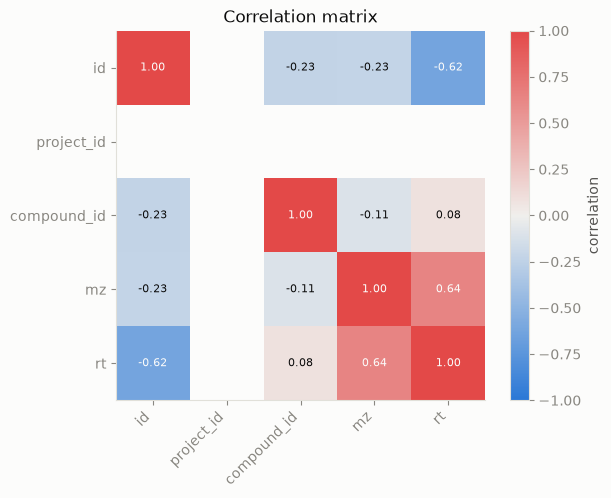

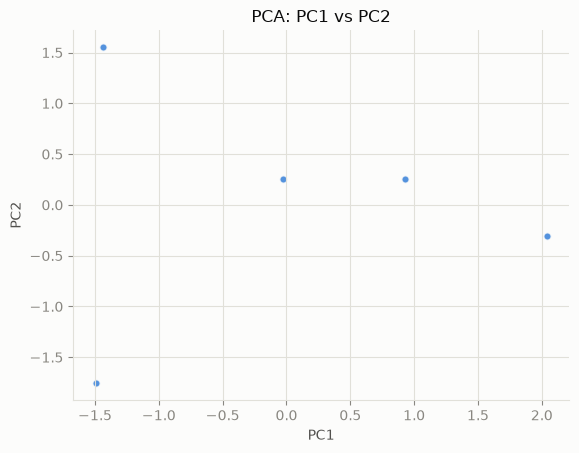

In [17]:
quick_report(project_compounds, target="rt")

### 3.2 Cleaning steps: `impute` / `normalize` / `encode`

These mutate `.df` and return `self`, so they chain. Shown here on a scratch
copy so the raw units stay available for the analysis steps below.

In [18]:
cleaned = (
    Dataset(project_compounds)
    .impute(columns=["mz", "rt", "intensity"], method="mean")
    .normalize(columns=["mz", "rt", "intensity"], method="zscore")
)
cleaned.df[["mz", "rt", "intensity"]].describe()

KeyError: 'intensity'

In [ ]:
encoded = Dataset(project_compounds).encode(columns=["sample_group"], method="onehot")
[c for c in encoded.df.columns if c.startswith("sample_group")]

### 3.3 Step by step: `Dataset`

In [ ]:
ds = Dataset(project_compounds)
ds.summary()

In [ ]:
ds.correlation(columns=["mz", "rt", "intensity"])

In [ ]:
# hue can be any column from the original data, even one PCA itself never saw
pca_result = ds.pca(columns=["mz", "rt", "intensity"], hue="sample_group")
pca_result

In [ ]:
cluster_result = ds.cluster(columns=["mz", "rt", "intensity"], k=3)
cluster_result

k-means never sees `sample_group` — compare its 3 clusters to the true groups:

In [ ]:
pd.crosstab(
    pd.Series([row["sample_group"] for row in project_compounds], name="true group"),
    pd.Series(cluster_result.labels, name="cluster"),
)

In [ ]:
regression_result = ds.regression(target="intensity", features=["mz", "rt"])
regression_result

In [ ]:
regression_result.coefficients

In [ ]:
# reuse the normalized `cleaned` dataset from above — unscaled mz/rt/intensity
# (raw units in the hundreds) make logistic regression's solver converge poorly
classification_result = cleaned.classify(target="is_mapped", features=["mz", "rt", "intensity"])
classification_result

## 3.4 Statistical tests

In [ ]:
ds.anova(group_col="sample_group", value_col="intensity")

In [ ]:
ds.ttest(group_col="is_mapped", value_col="mz")

In [ ]:
ds.chi_square(col1="sample_group", col2="is_mapped")